# Cash flow analysis: the Pizzeria Amalfi bank statement

The agent plans with this bank statement, so here we look at it by hand first.
Everything is read from the app's own API (`/api/v1`) from this workbench, which runs in the same OpenShift project.
The api's NetworkPolicy only lets in the web, ai and workbench pods, so the notebook uses the same way in as the app
and never opens the database directly.

The API sends amounts in cents. They are turned into euros here.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import requests
from matplotlib.ticker import FuncFormatter

API = "http://api.autonomous-cfo.svc.cluster.local:8080/api/v1"


def get(path, **params):
    r = requests.get(f"{API}{path}", params=params, timeout=30)
    r.raise_for_status()
    return r.json()


def eur(cents):
    return int(cents) / 100

plt.rcParams.update({
    "font.size": 10,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3",
    "axes.labelcolor": "#52514e",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
EUR = FuncFormatter(lambda v, _: f"{v:,.0f} €")
pd.set_option("display.max_colwidth", None)

In [2]:
company = get("/company")
mandate = get("/mandate")
floor = eur(mandate["cash_floor"])
pd.Series({
    "company": company["name"],
    "today in the demo": company["as_of_date"],
    "statement until": company["statement_until"],
    "balance (EUR)": eur(company["balance"]),
    "cash floor (EUR)": floor,
    "protected categories": ", ".join(mandate["protected_categories"]),
}, name="value")

company                               Pizzeria Amalfi
today in the demo                          2025-05-05
statement until                            2025-05-04
balance (EUR)                                  401.96
cash floor (EUR)                              -5000.0
protected categories    PAYROLL, SOCIAL_SECURITY, TAX
Name: value, dtype: object

In [3]:
tx = pd.DataFrame(get("/transactions"))
tx["date"] = pd.to_datetime(tx["booking_date"])
tx["eur"] = tx["amount"].map(eur)
print(len(tx), "bookings from", tx["date"].min().date(), "to", tx["date"].max().date())
tx.groupby("category")["eur"].agg(["count", "sum"]).round(2).sort_values("sum")

414 bookings from 2025-01-01 to 2025-05-04


,count,sum
category,,
VARIABLE_COST,199,-95095.76
PAYROLL,16,-34400.00
RENT,5,-19000.00
PARTNER_TRANSFER,4,-17354.18
SOCIAL_SECURITY,4,-10600.00
TAX,6,-4895.00
UTILITIES,4,-2600.00
CARD_REVENUE,176,181846.90


## 1. Month by month

Net amount per category and month. May only has its first four days, because the demo's "today" is 5 May 2025.

In [4]:
tx["month"] = tx["date"].dt.strftime("%Y-%m")
monthly = tx.pivot_table(index="category", columns="month", values="eur", aggfunc="sum", fill_value=0).round(0)
monthly.loc["NET"] = monthly.sum()
monthly

month,2025-01,2025-02,2025-03,2025-04,2025-05
category,,,,,
CARD_REVENUE,45760.0,42011.0,45720.0,43718.0,4638.0
PARTNER_TRANSFER,-4342.0,-4354.0,-4325.0,-4333.0,0.0
PAYROLL,-8600.0,-8600.0,-8600.0,-8600.0,0.0
RENT,-3800.0,-3800.0,-3800.0,-3800.0,-3800.0
SOCIAL_SECURITY,-2650.0,-2650.0,-2650.0,-2650.0,0.0
TAX,-880.0,-1105.0,-2030.0,-880.0,0.0
UTILITIES,-650.0,-650.0,-650.0,-650.0,0.0
VARIABLE_COST,-24291.0,-22134.0,-24092.0,-21764.0,-2815.0
NET,547.0,-1282.0,-427.0,1041.0,-1977.0


## 2. Daily balance since January

The statement has no running balance column, so the end of day balance is rebuilt backwards from today's balance.

In [5]:
days = pd.date_range(tx["date"].min(), tx["date"].max())
net = tx.groupby("date")["eur"].sum().reindex(days, fill_value=0)
after = net[::-1].cumsum()[::-1].shift(-1, fill_value=0)
closing = eur(company["balance"]) - after

low_day = closing.idxmin()
pd.Series({
    "lowest balance (EUR)": round(closing[low_day], 2),
    "lowest on": low_day.date(),
    "highest balance (EUR)": round(closing.max(), 2),
    "days below the cash floor": int((closing < floor).sum()),
}, name="Jan - May 2025")

lowest balance (EUR)           -2777.85
lowest on                    2025-04-03
highest balance (EUR)          11368.68
days below the cash floor             0
Name: Jan - May 2025, dtype: object

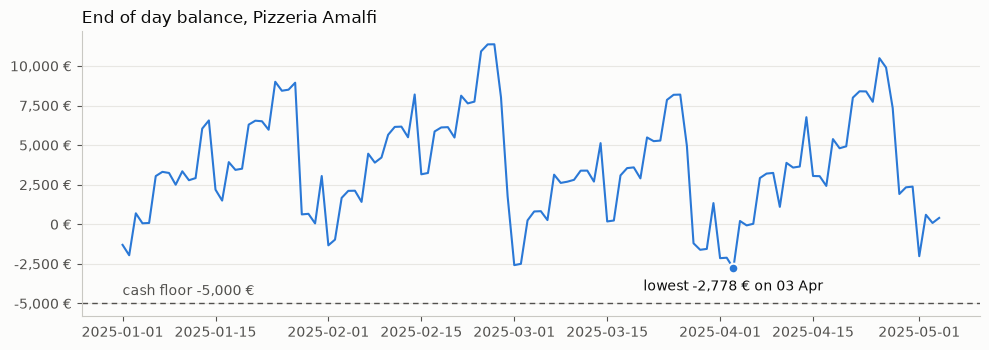

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(closing.index, closing.values, color=BLUE, linewidth=1.5, solid_joinstyle="round")
ax.axhline(floor, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate(f"cash floor {floor:,.0f} €", (closing.index[0], floor), textcoords="offset points",
            xytext=(0, 6), color=MUTED)
ax.plot([low_day], [closing[low_day]], marker="o", markersize=7, color=BLUE,
        markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.annotate(f"lowest {closing[low_day]:,.0f} € on {low_day:%d %b}", (low_day, closing[low_day]),
            textcoords="offset points", xytext=(0, -16), ha="center", color=INK)
ax.yaxis.set_major_formatter(EUR)
ax.set_title("End of day balance, Pizzeria Amalfi", loc="left")
fig.tight_layout()
plt.show()

## 3. Card revenue by weekday

The forecast is not a black box: `/revenue-model` says it uses weekday averages over the last weeks.
Here the same averages are computed again from the raw bookings, to check the backend's numbers.

In [7]:
rm = get("/revenue-model")
window = tx[(tx["date"] >= rm["window_from"]) & (tx["date"] <= rm["window_to"])].copy()
window["weekday"] = window["date"].dt.dayofweek
cents = window.assign(c=window["amount"].astype(int))


def weekday_avg(category):
    total = cents[cents["category"] == category].groupby("weekday")["c"].sum()
    return (total.reindex(range(7), fill_value=0) / rm["weeks"] / 100).round(2).values


api = pd.DataFrame(rm["by_weekday"])
check = pd.DataFrame({
    "weekday": api["weekday"],
    "revenue (api)": api["revenue"].map(eur),
    "revenue (recomputed)": weekday_avg("CARD_REVENUE"),
    "variable costs (api)": api["variable_costs"].map(eur),
    "variable costs (recomputed)": weekday_avg("VARIABLE_COST"),
})
check["max difference (EUR)"] = (
    (check["revenue (api)"] - check["revenue (recomputed)"]).abs()
    .combine((check["variable costs (api)"] - check["variable costs (recomputed)"]).abs(), max)
    .round(2)
)
print(rm["method"], "|", rm["window_from"], "to", rm["window_to"], "|", rm["weeks"], "weeks |", rm["model_version"])
check

WEEKDAY_AVERAGE | 2025-03-10 to 2025-05-04 | 8 weeks | revenue-1.0.0


,weekday,revenue (api),revenue (recomputed),variable costs (api),variable costs (recomputed),max difference (EUR)
0,MON,4044.72,4044.72,-1124.71,-1124.71,0.00
1,TUE,1277.78,1277.79,-852.06,-852.05,0.01
2,WED,259.89,259.89,-240.26,-240.25,0.01
3,THU,257.04,257.05,-896.96,-896.95,0.01
4,FRI,3852.97,3852.98,-1158.77,-1158.76,0.01
5,SAT,349.74,349.74,-790.97,-790.96,0.01
6,SUN,338.50,338.51,-231.89,-231.89,0.01


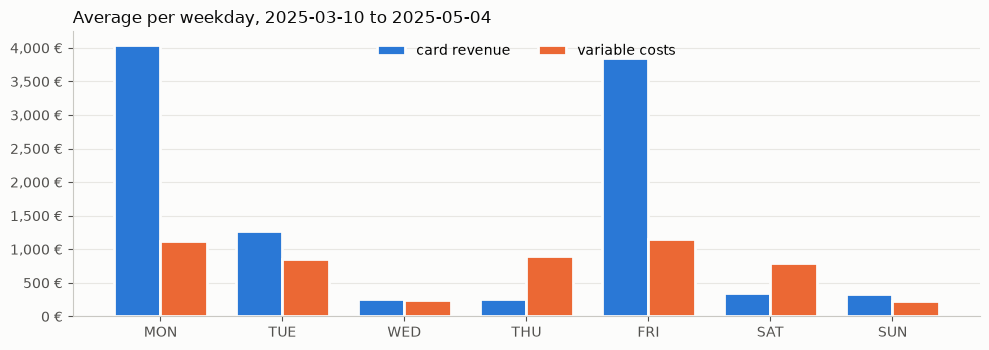

In [8]:
x = range(len(check))
width = 0.38
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar([i - width / 2 for i in x], check["revenue (api)"], width, color=BLUE, edgecolor=SURFACE,
       linewidth=2, label="card revenue")
ax.bar([i + width / 2 for i in x], -check["variable costs (api)"], width, color=ORANGE, edgecolor=SURFACE,
       linewidth=2, label="variable costs")
ax.set_xticks(list(x), check["weekday"])
ax.yaxis.set_major_formatter(EUR)
ax.legend(loc="upper center", ncol=2)
ax.set_title(f"Average per weekday, {rm['window_from']} to {rm['window_to']}", loc="left")
fig.tight_layout()
plt.show()

## 4. Payments the agent can and cannot move

The known outflows after today. Categories on the mandate's protected list are never moved by the agent.

In [9]:
out = pd.DataFrame(get("/outflows"))
out["eur"] = out["amount"].map(eur)
out["can be moved"] = ~out["protected"]
out.sort_values(["due_date", "ref"]).reset_index(drop=True)[
    ["due_date", "ref", "counterparty", "category", "eur", "original_currency", "can be moved"]
]

,due_date,ref,counterparty,category,eur,original_currency,can be moved
0,2025-05-10,UTIL-05,City Energy & Utilities AG,UTILITIES,650.00,None,True
1,2025-05-10,WTAX-05,Tax Office Frankfurt am Main,TAX,880.00,None,False
2,2025-05-15,CHF-05,Luigi Amalfi (Luigi's Ristorante Zurich),PARTNER_TRANSFER,4333.34,CHF,True
3,2025-05-15,TTAX-05,Tax Office Frankfurt am Main,TAX,225.00,None,False
4,2025-05-27,SOC-05,Techniker Krankenkasse Social Health Fund,SOCIAL_SECURITY,2650.00,None,False
5,2025-05-28,PAY-05,Payroll (4 people),PAYROLL,8600.00,None,False
6,2025-06-01,RENT-06,Main Street Real Estate GmbH,RENT,3800.00,None,True
7,2025-06-10,ITAX-06,Tax Office Frankfurt am Main,TAX,1150.00,None,False
8,2025-06-10,UTIL-06,City Energy & Utilities AG,UTILITIES,650.00,None,True
9,2025-06-10,WTAX-06,Tax Office Frankfurt am Main,TAX,880.00,None,False


In [10]:
out.groupby(["can be moved", "category"])["eur"].agg(["count", "sum"]).round(2)

count       sum
can be moved category                         
False        PAYROLL               3  25800.00
             SOCIAL_SECURITY       3   7950.00
             TAX                   5   4015.00
True         PARTNER_TRANSFER      3  13000.02
             RENT                  3  11400.00
             UTILITIES             3   1950.00

## 5. Payments in Swiss francs

The partner in Zurich is paid in CHF, so the euro amount of the same transfer changes with the exchange rate.

In [11]:
fx = tx[tx["original_currency"].notna()].copy()
fx["chf"] = fx["original_amount"].map(eur)
fx["fx_rate"] = fx["fx_rate"].astype(float)
fx[["booking_date", "counterparty", "chf", "fx_rate", "eur"]]

,booking_date,counterparty,chf,fx_rate,eur
48,2025-01-15,Luigi Amalfi (Luigi's Ristorante Zurich),-4166.67,1.042,-4341.67
152,2025-02-15,Luigi Amalfi (Luigi's Ristorante Zurich),-4166.67,1.045,-4354.17
250,2025-03-15,Luigi Amalfi (Luigi's Ristorante Zurich),-4166.67,1.038,-4325.00
352,2025-04-15,Luigi Amalfi (Luigi's Ristorante Zurich),-4166.67,1.040,-4333.34


In [12]:
upcoming_fx = out[out["original_currency"].notna()].copy()
upcoming_fx["chf"] = upcoming_fx["original_amount"].map(eur)
upcoming_fx[["due_date", "ref", "counterparty", "chf", "eur", "can be moved"]]

,due_date,ref,counterparty,chf,eur,can be moved
2,2025-05-15,CHF-05,Luigi Amalfi (Luigi's Ristorante Zurich),4166.67,4333.34,True
10,2025-06-15,CHF-06,Luigi Amalfi (Luigi's Ristorante Zurich),4166.67,4333.34,True
16,2025-07-15,CHF-07,Luigi Amalfi (Luigi's Ristorante Zurich),4166.67,4333.34,True


## What we take from it

- January to April the pizzeria is close to break even: card revenue of about 42 000 - 46 000 € a month,
  a monthly net between -1 282 € and +1 041 €.
- The balance stayed between -2 778 € (3 April) and 11 369 €. It never went below the -5 000 € floor,
  but the margin is thin: one month without revenue would break it.
- Card revenue is booked mostly on Mondays and Fridays, so a plain daily average would be wrong on most days.
  The forecast works per weekday, and our own recomputation of `/revenue-model` matches the backend
  to the cent (differences of at most 0.01 € are rounding).
- Until 1 August 37 765 € of the known payments are protected (payroll, social security, tax).
  Only 26 350 € (partner transfer, rent, utilities) are payments the agent may propose to move.
- The partner in Zurich gets the same 4 166.67 CHF every month, which cost between 4 325.00 € and 4 354.17 €
  so far (rate 1.038 - 1.045).